# mel_sandbox_data_4: Stimulation current (Data task, item 4)

The Problem Statement says the current was 8 mA, but 4 mA near the sensorimotor cortex
(`stimpair_currents`), and asks us to decide how to take this into account.

Before deciding, this notebook checks:

1. What `stimpair_currents` looks like (units, format).
2. Which current values occur, and how often.
3. Whether the low-current pairs really are near the sensorimotor cortex.
4. Whether a lower current gives fewer N1 responses.

**Note:** the N1 rate here is a rough one: share of *good channels* with an N1, **before** our
exclusion rules (13 mm, resected, SOZ, ...). It is only meant to show whether the current matters.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.paths import load_ccep, runs

cc = load_ccep()
print(len(cc), "patients")

74 patients


## 1. What does `stimpair_currents` look like?

- One entry per stimulation pair (same length as `stimpair_names`).
- The values are in **amperes** (0.008 = 8 mA).
- Usually one number per pair, but in a few runs a pair has **two** values
  (the pair was stimulated with two different currents in the same run).

In [2]:
r = runs(cc[0])[1]
print(r["runName"])
print("pairs:", len(r["stimpair_names"]), "| currents:", len(r["stimpair_currents"]))
for name, cur in list(zip(r["stimpair_names"], r["stimpair_currents"]))[:4]:
    print(f"  {name:12s} -> {cur}")

sub-ccepAgeUMCU01_ses-1_task-SPESclin_run-031422_averageCCEPs.mat
pairs: 31 | currents: 31
  vT1-vT2      -> 0.007
  vT3-vT2      -> 0.007
  vT3-vT4      -> [0.006 0.007]
  sT1-sT2      -> 0.006


## 2. One table with one row per stimulation pair

For each pair we store:

- `currents`: the current(s) in mA (a tuple, because a few pairs have two values).
- `current_cat`: a readable category, e.g. `"8 mA"` or `"mixed 4/8"`.
- `sensorimotor`: True if at least one of the two stimulated electrodes lies in a sensorimotor
  Destrieux region (list below).
- `n1_rate`: share of good channels with an N1 (rough, no exclusions).

In [3]:
# Destrieux numbers of the sensorimotor regions (checked against lut_aparc-a2009s_mics.csv)
SENSORIMOTOR = {
    3: "G_and_S_paracentral",
    4: "G_and_S_subcentral",
    28: "G_postcentral",
    29: "G_precentral",
    46: "S_central",
}


def to_int(x):
    try:
        return int(x)
    except (TypeError, ValueError):
        return -1  # missing label


rows = []
for p in cc:
    for r in runs(p):
        n1 = np.asarray(r["n1_peak_sample"], dtype=float)          # channels x stimulation pairs
        good = np.zeros(n1.shape[0], dtype=bool)
        good[np.atleast_1d(r["good_channels"]).astype(int) - 1] = True   # MATLAB indices start at 1
        labels = np.asarray(r["stimpair_DestrieuxNr"]).reshape(-1, 2)
        assert len(r["stimpair_currents"]) == len(r["stimpair_names"]) == n1.shape[1], p["id"]

        for j, (name, cur) in enumerate(zip(r["stimpair_names"], r["stimpair_currents"])):
            mA = np.round(np.atleast_1d(np.asarray(cur, dtype=float)) * 1000, 3)
            a, b = to_int(labels[j, 0]), to_int(labels[j, 1])
            rows.append({
                "patient": p["id"],
                "run": r["runName"],
                "pair": name,
                "currents": tuple(sorted(set(mA.tolist()))),
                "sensorimotor": (a in SENSORIMOTOR) or (b in SENSORIMOTOR),
                "n1_rate": np.mean(~np.isnan(n1[good, j])),
            })

pairs = pd.DataFrame(rows)
pairs["current_cat"] = pairs["currents"].map(
    lambda t: f"{t[0]:g} mA" if len(t) == 1 else "mixed " + "/".join(f"{x:g}" for x in t)
)
print(len(pairs), "stimulation pairs")
pairs.head()

4907 stimulation pairs


,patient,run,pair,currents,sensorimotor,n1_rate,current_cat
0,sub-ccepAgeUMCU01,sub-ccepAgeUMCU01_ses-1_task-SPESclin_run-0214...,PT01-PT02,"(7.0,)",False,0.039216,7 mA
1,sub-ccepAgeUMCU01,sub-ccepAgeUMCU01_ses-1_task-SPESclin_run-0214...,PT03-PT02,"(7.0,)",False,0.078431,7 mA
2,sub-ccepAgeUMCU01,sub-ccepAgeUMCU01_ses-1_task-SPESclin_run-0214...,PT03-PT04,"(7.0,)",False,0.039216,7 mA
3,sub-ccepAgeUMCU01,sub-ccepAgeUMCU01_ses-1_task-SPESclin_run-0214...,PT05-PT04,"(7.0,)",False,0.039216,7 mA
4,sub-ccepAgeUMCU01,sub-ccepAgeUMCU01_ses-1_task-SPESclin_run-0214...,PT05-PT06,"(7.0,)",False,0.019608,7 mA


## 3. Which currents occur?

The Problem Statement mentions only 8 and 4 mA, but the data also has 7, 6 and 2 mA,
plus a few "mixed" pairs.

In [4]:
counts = pd.DataFrame({
    "pairs": pairs["current_cat"].value_counts(),
    "patients": pairs.groupby("current_cat")["patient"].nunique(),
}).sort_values("pairs", ascending=False)
counts["% of pairs"] = (100 * counts["pairs"] / len(pairs)).round(1)
counts

,pairs,patients,% of pairs
current_cat,,,
8 mA,4336,73,88.4
4 mA,296,18,6.0
7 mA,218,1,4.4
6 mA,43,4,0.9
2 mA,6,1,0.1
mixed 4/8,5,4,0.1
mixed 6/7,2,1,0.0
mixed 6/8,1,1,0.0


In [5]:
# Which patients have pairs that are not 8 mA?
pairs[pairs["current_cat"] != "8 mA"].groupby(["patient", "current_cat"]).size().unstack(fill_value=0)

current_cat,2 mA,4 mA,6 mA,7 mA,mixed 4/8,mixed 6/7,mixed 6/8
patient,,,,,,,
sub-ccepAgeUMCU01,0,0,2,218,0,2,0
sub-ccepAgeUMCU02,0,0,11,0,0,0,1
sub-ccepAgeUMCU09,0,0,2,0,0,0,0
sub-ccepAgeUMCU12,0,0,28,0,0,0,0
sub-ccepAgeUMCU21,0,4,0,0,2,0,0
sub-ccepAgeUMCU29,0,4,0,0,1,0,0
sub-ccepAgeUMCU33,0,9,0,0,0,0,0
sub-ccepAgeUMCU34,6,23,0,0,0,0,0
sub-ccepAgeUMCU36,0,10,0,0,0,0,0


## 4. Are the low-current pairs near the sensorimotor cortex?

If the Problem Statement is right, most 4 mA pairs should be sensorimotor.

In [6]:
ct = pd.crosstab(pairs["current_cat"], pairs["sensorimotor"], margins=True)
ct.columns = ["not sensorimotor", "sensorimotor", "all"]
ct["% sensorimotor"] = (100 * ct["sensorimotor"] / ct["all"]).round(0)
ct

,not sensorimotor,sensorimotor,all,% sensorimotor
current_cat,,,,
2 mA,3,3,6,50.0
4 mA,136,160,296,54.0
6 mA,20,23,43,53.0
7 mA,198,20,218,9.0
8 mA,3475,861,4336,20.0
mixed 4/8,2,3,5,60.0
mixed 6/7,2,0,2,0.0
mixed 6/8,1,0,1,0.0
All,3837,1070,4907,22.0


## 5. Does a lower current give fewer N1s?

Comparing all 4 mA pairs with all 8 mA pairs is not fair: they come from different patients and
different brain regions. So we compare **within each patient**: for every patient who has both
4 mA and 8 mA pairs, we take the mean N1 rate of each group.

- **Left:** all pairs of these patients.
- **Right:** only sensorimotor pairs, so the brain region is (roughly) the same for both currents.

Each line is one patient. A line going up from 4 mA to 8 mA means more N1s at 8 mA.

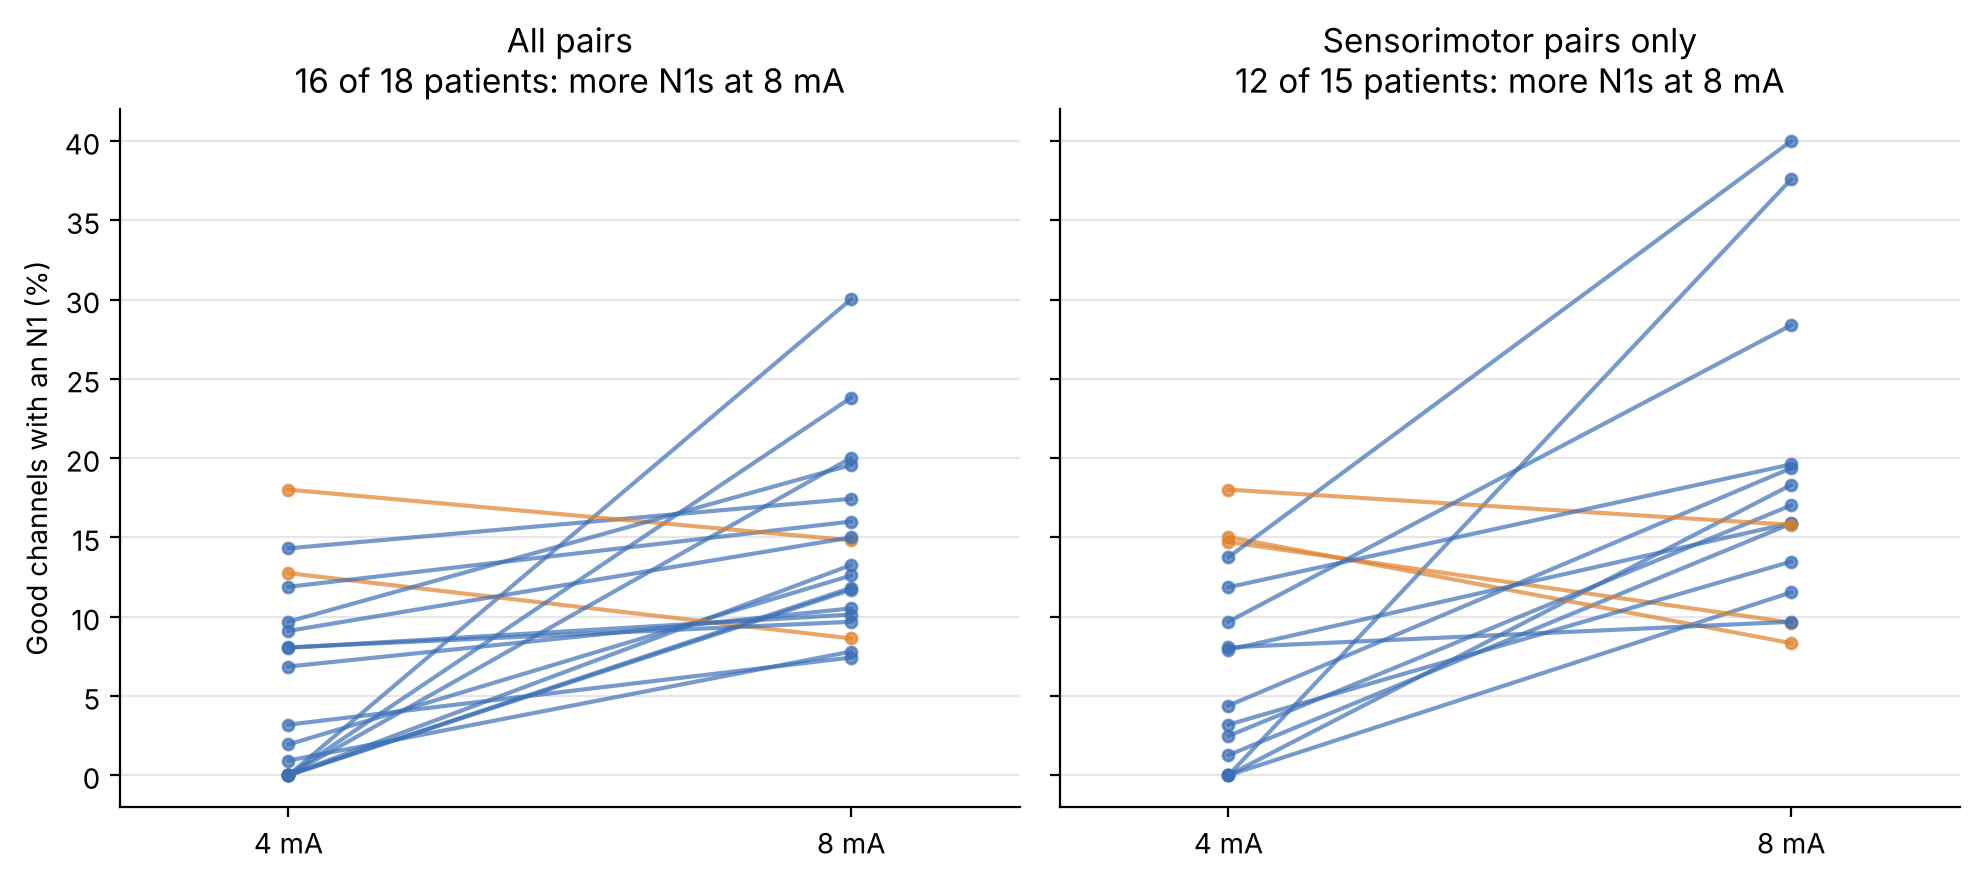

All pairs: median difference (8 mA - 4 mA) = 6.4 percentage points, n = 18 patients
Sensorimotor pairs only: median difference (8 mA - 4 mA) = 11.5 percentage points, n = 15 patients


In [7]:
def within_patient(df):
    sub = df[df["current_cat"].isin(["4 mA", "8 mA"])]
    return sub.groupby(["patient", "current_cat"])["n1_rate"].mean().unstack().dropna()


comparisons = [
    ("All pairs", within_patient(pairs)),
    ("Sensorimotor pairs only", within_patient(pairs[pairs["sensorimotor"]])),
]

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
for ax, (title, pp) in zip(axes, comparisons):
    for _, row in pp.iterrows():
        up = row["8 mA"] > row["4 mA"]
        ax.plot([0, 1], 100 * row[["4 mA", "8 mA"]].values, marker="o", ms=4,
                color="#3b6fb6" if up else "#e0812c", alpha=0.7)
    n_up = (pp["8 mA"] > pp["4 mA"]).sum()
    ax.set_xticks([0, 1], ["4 mA", "8 mA"])
    ax.set_xlim(-0.3, 1.3)
    ax.set_title(f"{title}\n{n_up} of {len(pp)} patients: more N1s at 8 mA")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("Good channels with an N1 (%)")
plt.tight_layout()
plt.show()

for title, pp in comparisons:
    diff = 100 * (pp["8 mA"] - pp["4 mA"])
    print(f"{title}: median difference (8 mA - 4 mA) = {diff.median():.1f} percentage points, n = {len(pp)} patients")

## 5b. Careful: pairs with no N1 at all

Several patients sit at exactly 0% at 4 mA. A pair with **no N1 on any channel** can mean two things:
the low current really evoked nothing, or the N1 detection was not run for that pair (both look like
all-NaN in `n1_peak_sample`). We cannot tell them apart from this file alone, so we check how often it happens.

In [8]:
pairs["no_n1_at_all"] = pairs["n1_rate"] == 0
print((100 * pairs.groupby("current_cat")["no_n1_at_all"].mean()).round(1).rename("% of pairs with no N1 at all"))

low = pairs[pairs["current_cat"] == "4 mA"]
all_zero = low.groupby("patient")["no_n1_at_all"].all()
print()
print("Patients where EVERY 4 mA pair has no N1:", list(all_zero[all_zero].index))

current_cat
2 mA         100.0
4 mA          26.4
6 mA           2.3
7 mA           0.0
8 mA          11.9
mixed 4/8     60.0
mixed 6/7      0.0
mixed 6/8    100.0
Name: % of pairs with no N1 at all, dtype: float64

Patients where EVERY 4 mA pair has no N1: ['sub-ccepAgeUMCU21', 'sub-ccepAgeUMCU29', 'sub-ccepAgeUMCU36', 'sub-ccepAgeUMCU48', 'sub-ccepAgeUMCU53', 'sub-ccepAgeUMCU57']


## 6. What to look for / open decisions

- **More values than expected.** 4 and 8 mA are not the only currents: 7, 6 and 2 mA also occur
  (mostly in a few patients, e.g. UMCU01 is almost entirely 7 mA). So "8 vs 4" is too simple.
  Options for the covariate:
  - (a) current in mA as a number (2-8);
  - (b) two groups: full current (8 mA) vs reduced (< 8 mA).
- **Mixed pairs** (two currents in one run): only a handful. Simplest: use the lower value, or drop them.
- **Not only sensorimotor.** Only about half of the 4 mA pairs are sensorimotor, and many sensorimotor
  pairs were stimulated at 8 mA. So current and region are related, but not the same thing; this helps
  the covariate, because the model can separate them a bit.
- **The current matters.** If most lines in section 5 go up, a lower current really gives fewer N1s,
  also within sensorimotor pairs. So we should keep the current as a covariate in the Analysis, and
  repeat the analysis with 8 mA pairs only as a robustness check.
- **But check section 5b first.** In some patients every 4 mA pair has no N1 at all. If the N1
  detection was simply not run for those pairs, part of the 4 vs 8 mA difference is not a real effect.
  The data paper's Methods may say whether all pairs were analysed. Without such pairs, the difference
  would be smaller.
- Later, recompute the N1 rate **after** our exclusion rules to check that the picture stays the same.